In [ ]:
# Deep Learning Lab
# Experiment 3
# Implementation of Convolutional Neural Networks (CNNs) for Image Classification

# Mounting Google Drive
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Saving CIFAR-10 Dataset in drive
'''from tensorflow.keras.datasets import cifar10
import os
import numpy as np

# Create folder in Google Drive
drive_path = "/content/drive/MyDrive/Deep Learning/CIFAR-10"
os.makedirs(drive_path, exist_ok=True)

# Download CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Save the complete dataset to Google Drive
np.savez_compressed(
    os.path.join(drive_path, "cifar10_dataset.npz"),
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

print("CIFAR-10 saved successfully!")
print("Location:", drive_path)
print("Training data:", x_train.shape)
print("Testing data :", x_test.shape)'''

'from tensorflow.keras.datasets import cifar10\nimport os\nimport numpy as np\n\n# Create folder in Google Drive\ndrive_path = "/content/drive/MyDrive/Deep Learning/CIFAR-10"\nos.makedirs(drive_path, exist_ok=True)\n\n# Download CIFAR-10\n(x_train, y_train), (x_test, y_test) = cifar10.load_data()\n\n# Save the complete dataset to Google Drive\nnp.savez_compressed(\n    os.path.join(drive_path, "cifar10_dataset.npz"),\n    x_train=x_train,\n    y_train=y_train,\n    x_test=x_test,\n    y_test=y_test\n)\n\nprint("CIFAR-10 saved successfully!")\nprint("Location:", drive_path)\nprint("Training data:", x_train.shape)\nprint("Testing data :", x_test.shape)'

In [ ]:
# Task 1 : Dataset Exploration
# Loading CIFAR-10
import numpy as np
import os

drive_path = "/content/drive/MyDrive/Deep Learning/CIFAR-10"

data = np.load(
    os.path.join(drive_path, "cifar10_dataset.npz")
)

x_train = data["x_train"]
y_train = data["y_train"]
x_test = data["x_test"]
y_test = data["y_test"]

print("Training images :", x_train.shape)
print("Training labels :", y_train.shape)
print("Testing images  :", x_test.shape)
print("Testing labels  :", y_test.shape)

Training images : (50000, 32, 32, 3)
Training labels : (50000, 1)
Testing images  : (10000, 32, 32, 3)
Testing labels  : (10000, 1)


In [ ]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Number of classes:", len(class_names))

Number of classes: 10


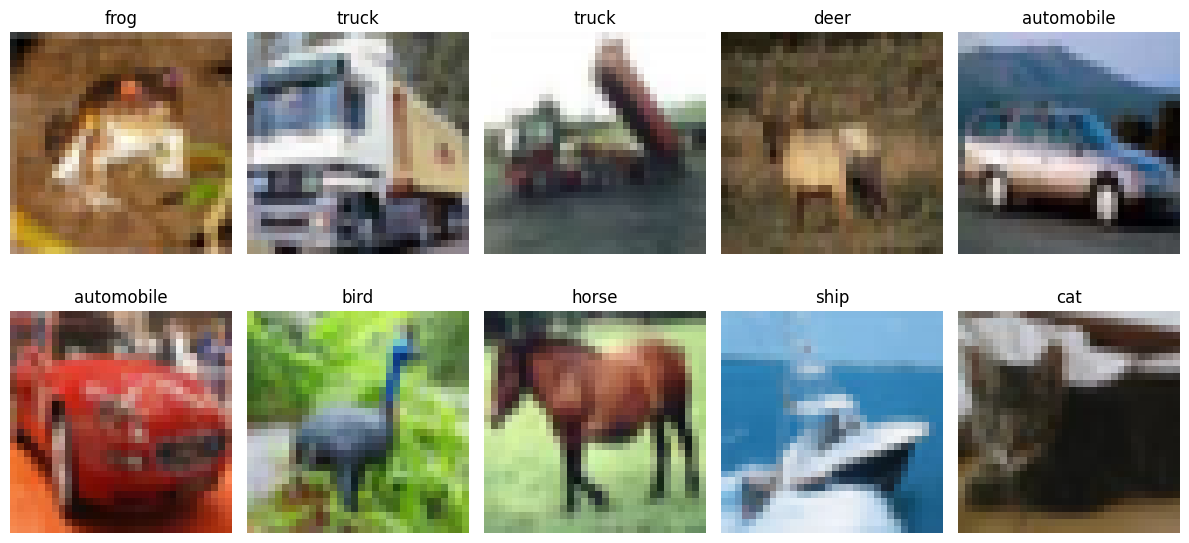

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.tight_layout()
plt.show()

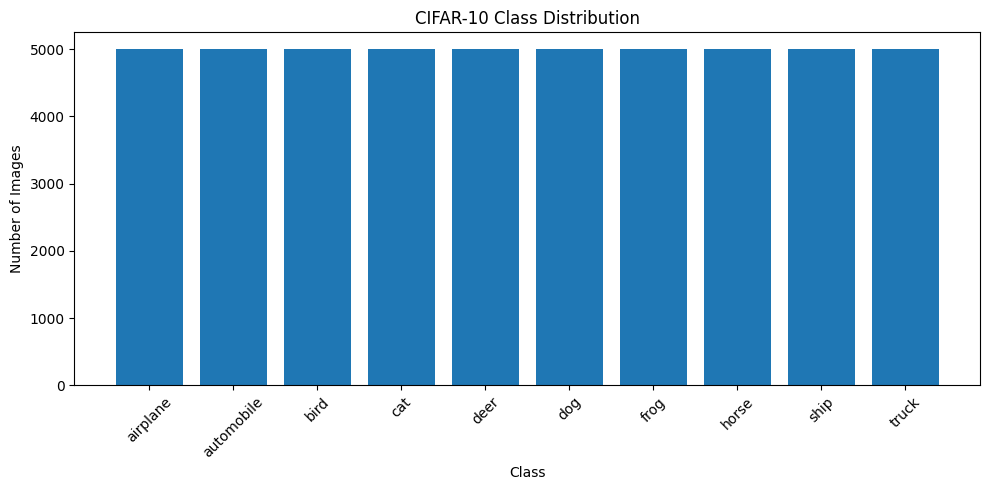

In [ ]:
unique_classes, class_counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(10, 5))

plt.bar(
    [class_names[i] for i in unique_classes],
    class_counts
)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("CIFAR-10 Class Distribution")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
print("\nNumber of classes:", len(class_names))
print("Image dimensions :", x_train.shape[1:])


Number of classes: 10
Image dimensions : (32, 32, 3)


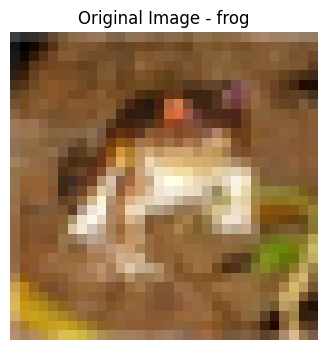

Original image shape: (32, 32, 3)
Image shape for Conv2D: (1, 32, 32, 3)


In [ ]:
# Select one image
image = x_train[0]

# Display the original image
plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(f"Original Image - {class_names[y_train[0][0]]}")
plt.axis("off")
plt.show()

# Add batch dimension
image_batch = np.expand_dims(image, axis=0)

print("Original image shape:", image.shape)
print("Image shape for Conv2D:", image_batch.shape)

Kernel: 3x3
Feature Map Size: (30, 30)

Kernel: 5x5
Feature Map Size: (28, 28)

Kernel: 7x7
Feature Map Size: (26, 26)



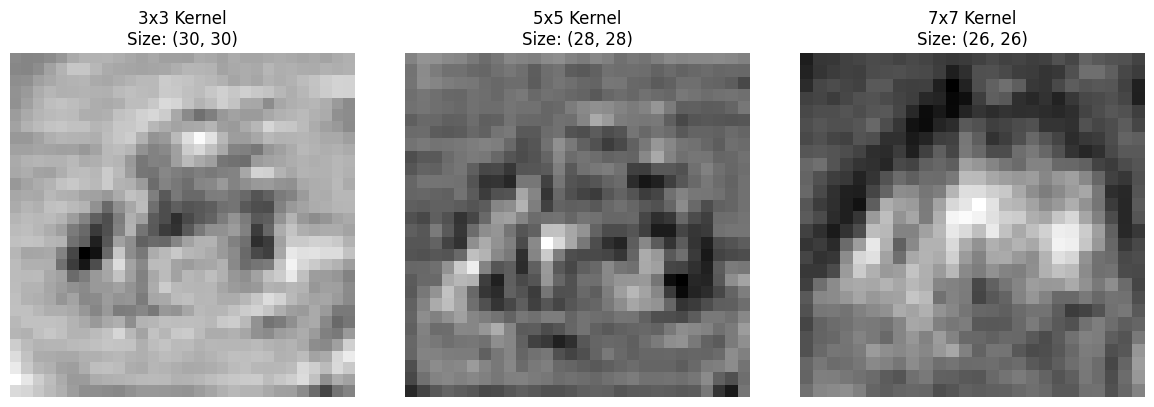

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Normalize images
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Take one image
image = x_train[0]

# Add batch dimension
image = tf.expand_dims(image, axis=0)

# Kernel sizes to compare
kernel_sizes = [3, 5, 7]

plt.figure(figsize=(12, 4))

for i, k in enumerate(kernel_sizes):

    # Create convolution layer
    conv = tf.keras.layers.Conv2D(
        filters=1,
        kernel_size=(k, k),
        strides=1,
        padding='valid'
    )

    # Apply convolution
    feature_map = conv(image)

    # Remove batch and channel dimensions
    feature_map = feature_map[0, :, :, 0]

    # Display feature map
    plt.subplot(1, 3, i + 1)
    plt.imshow(feature_map, cmap='gray')
    plt.title(f'{k}x{k} Kernel\nSize: {feature_map.shape}')
    plt.axis('off')

    print(f'Kernel: {k}x{k}')
    print(f'Feature Map Size: {feature_map.shape}')
    print()

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf

# Take one image
image = tf.expand_dims(x_train[0], axis=0)

# Compare stride and padding
settings = [
    (1, 'valid'),
    (2, 'valid'),
    (1, 'same'),
    (2, 'same')
]

for stride, padding in settings:

    conv = tf.keras.layers.Conv2D(
        filters=1,
        kernel_size=(3, 3),
        strides=stride,
        padding=padding
    )

    feature_map = conv(image)

    print(f"Stride = {stride}, Padding = {padding.upper()}")
    print("Output Shape:", feature_map.shape)
    print()

Stride = 1, Padding = VALID
Output Shape: (1, 30, 30, 1)

Stride = 2, Padding = VALID
Output Shape: (1, 15, 15, 1)

Stride = 1, Padding = SAME
Output Shape: (1, 32, 32, 1)

Stride = 2, Padding = SAME
Output Shape: (1, 16, 16, 1)



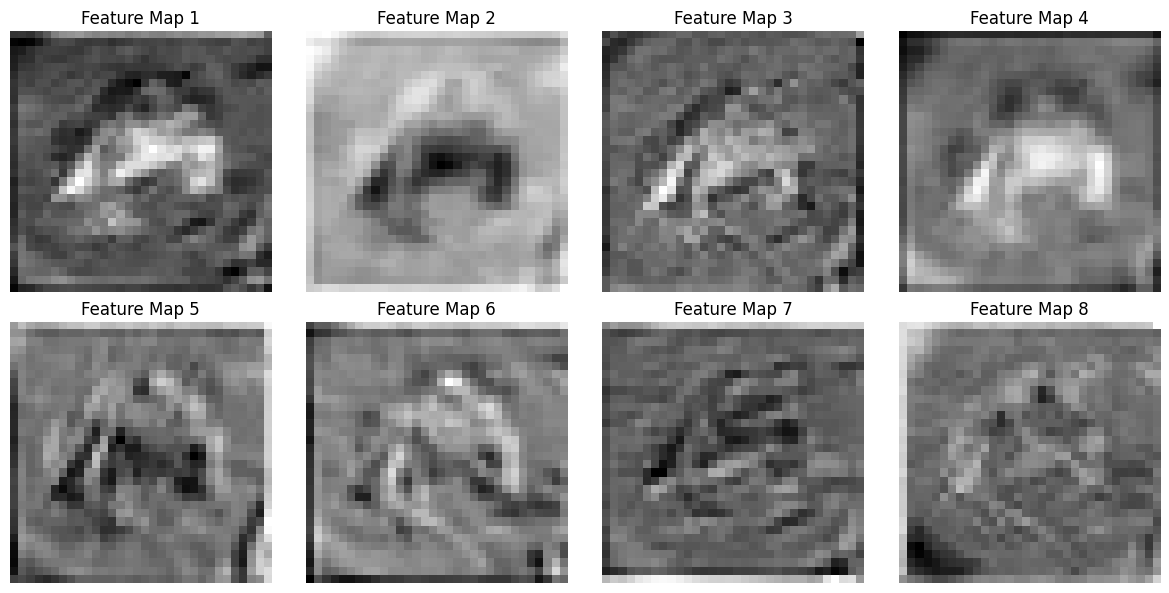

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Select one image
image = tf.expand_dims(x_train[0], axis=0)

# First convolution layer with 8 filters
conv = tf.keras.layers.Conv2D(
    filters=8,
    kernel_size=(3, 3),
    strides=1,
    padding='same'
)

# Generate feature maps
feature_maps = conv(image)

# Display 8 feature maps
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='gray')
    plt.title(f'Feature Map {i + 1}')
    plt.axis('off')

plt.tight_layout()
plt.show()

Original Feature Map Size: (32, 32)
Max Pooling Output Size: (16, 16)
Average Pooling Output Size: (16, 16)


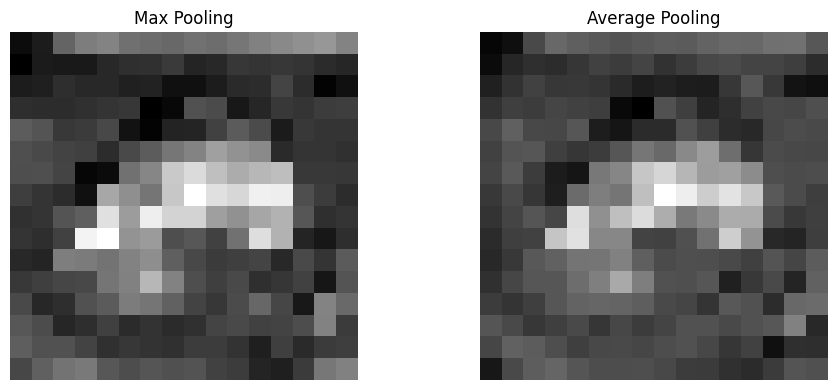

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Max Pooling
max_pool = tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=2
)

# Average Pooling
avg_pool = tf.keras.layers.AveragePooling2D(
    pool_size=(2, 2),
    strides=2
)

max_output = max_pool(feature_maps)
avg_output = avg_pool(feature_maps)

print("Original Feature Map Size:", feature_maps.shape[1:3])
print("Max Pooling Output Size:", max_output.shape[1:3])
print("Average Pooling Output Size:", avg_output.shape[1:3])

# Display comparison
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(max_output[0, :, :, 0], cmap='gray')
plt.title("Max Pooling")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(avg_output[0, :, :, 0], cmap='gray')
plt.title("Average Pooling")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Build CNN
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu',
                           padding='same', input_shape=(32, 32, 3)),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu',
                           padding='same'),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display architecture
model.summary()

# Train model
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.4805 - loss: 1.4522 - val_accuracy: 0.5688 - val_loss: 1.2189
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6207 - loss: 1.0746 - val_accuracy: 0.6093 - val_loss: 1.1242
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6765 - loss: 0.9252 - val_accuracy: 0.6585 - val_loss: 0.9925
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7100 - loss: 0.8303 - val_accuracy: 0.6710 - val_loss: 0.9546
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7436 - loss: 0.7370 - val_accuracy: 0.6735 - val_loss: 0.9552
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7699 - loss: 0.6583 - val_accuracy: 0.6790 - val_loss: 0.9639
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7936 - loss: 0.5843 - val_accuracy: 0.6815 - val_loss: 0.9810
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8196 - loss: 0.5117 -

In [ ]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Predictions
y_pred = model.predict(x_test)
y_pred = np.argmax(y_pred, axis=1)

y_true = y_test.flatten()

# Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=[
        'airplane', 'automobile', 'bird', 'cat', 'deer',
        'dog', 'frog', 'horse', 'ship', 'truck'
    ]
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Accuracy : 0.6674
Precision: 0.6706895006949976
Recall   : 0.6674
F1-Score : 0.667518375230663

Classification Report:
              precision    recall  f1-score   support

    airplane       0.75      0.67      0.70      1000
  automobile       0.78      0.80      0.79      1000
        bird       0.59      0.53      0.56      1000
         cat       0.45      0.45      0.45      1000
        deer       0.62      0.64      0.63      1000
         dog       0.54      0.58      0.56      1000
        frog       0.67      0.78      0.72      1000
       horse       0.68      0.77      0.72      1000
        ship       0.84      0.75      0.79      1000
       truck       0.79      0.71      0.75      1000

    accuracy                           0.67     10000
   macro avg       0.67      0.67      0.67     10000
weighted avg       0.67      0.67      0.67     10000



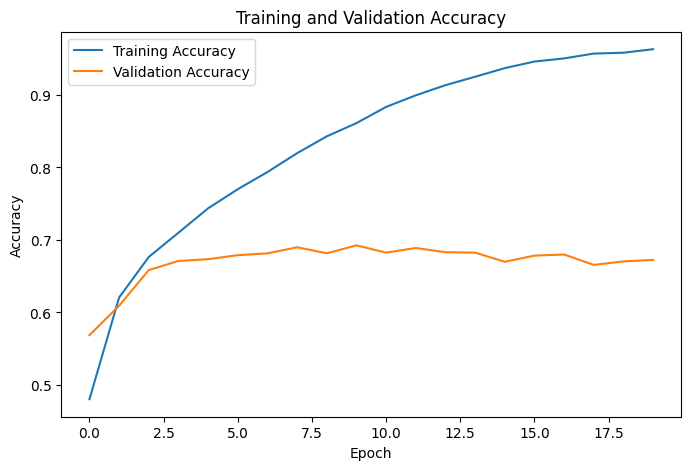

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.show()

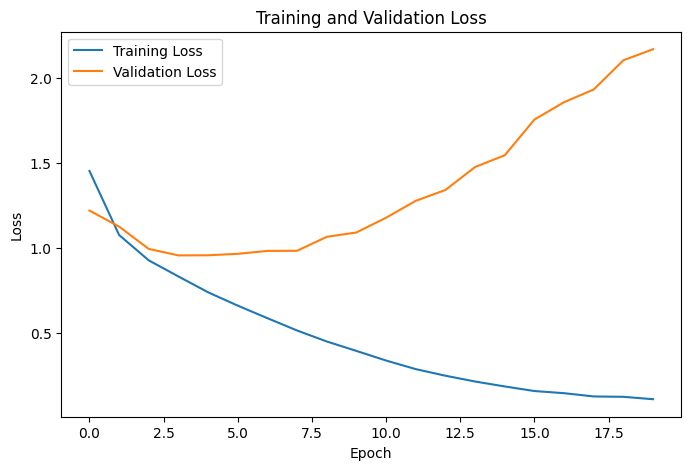

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.show()

In [ ]:
N = 64
F = 5
S = 2
P = 2

output_size = (N - F + 2 * P) // S + 1

print("Output Size:", output_size, "x", output_size)

Output Size: 32 x 32


In [ ]:
filters = 64
kernel_size = 3
input_channels = 3

parameters_per_filter = (kernel_size * kernel_size * input_channels) + 1
total_parameters = parameters_per_filter * filters

print("Parameters per filter:", parameters_per_filter)
print("Total Trainable Parameters:", total_parameters)

Parameters per filter: 28
Total Trainable Parameters: 1792


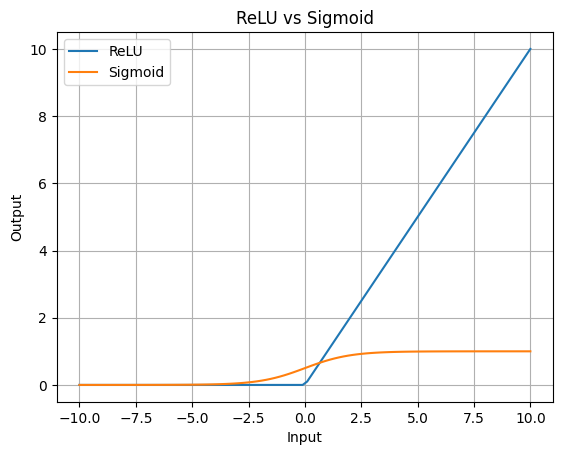

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 100)

relu = np.maximum(0, x)
sigmoid = 1 / (1 + np.exp(-x))

plt.plot(x, relu, label='ReLU')
plt.plot(x, sigmoid, label='Sigmoid')

plt.xlabel('Input')
plt.ylabel('Output')
plt.title('ReLU vs Sigmoid')
plt.legend()
plt.grid()

plt.show()

In [ ]:
import tensorflow as tf

max_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

max_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

max_model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

max_loss, max_accuracy = max_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Max Pooling Accuracy:", max_accuracy)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4962 - loss: 1.4105 - val_accuracy: 0.6025 - val_loss: 1.1454
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6388 - loss: 1.0300 - val_accuracy: 0.6159 - val_loss: 1.1191
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.6894 - loss: 0.8773 - val_accuracy: 0.6803 - val_loss: 0.9272
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7324 - loss: 0.7639 - val_accuracy: 0.6875 - val_loss: 0.9148
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7650 - loss: 0.6665 - val_accuracy: 0.6963 - val_loss: 0.8938
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7953 - loss: 0.5784 - val_accuracy: 0.6998 - val_loss: 0.9253
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.8282 - loss: 0.4871 - val_accuracy: 0.7063 - val_loss: 0.9384
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8584 - loss: 0.4074 -

In [ ]:
avg_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.AveragePooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.AveragePooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

avg_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

avg_model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

avg_loss, avg_accuracy = avg_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Average Pooling Accuracy:", avg_accuracy)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.4554 - loss: 1.5097 - val_accuracy: 0.5340 - val_loss: 1.3289
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5837 - loss: 1.1677 - val_accuracy: 0.6109 - val_loss: 1.0997
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6438 - loss: 1.0074 - val_accuracy: 0.6438 - val_loss: 1.0151
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6847 - loss: 0.8907 - val_accuracy: 0.6604 - val_loss: 0.9720
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7194 - loss: 0.7977 - val_accuracy: 0.6710 - val_loss: 0.9396
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7485 - loss: 0.7106 - val_accuracy: 0.6820 - val_loss: 0.9443
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7757 - loss: 0.6353 - val_accuracy: 0.7017 - val_loss: 0.8934
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8026 - loss: 0.5560 - 

In [ ]:
print("Max Pooling Accuracy    :", max_accuracy)
print("Average Pooling Accuracy:", avg_accuracy)

Max Pooling Accuracy    : 0.6705999970436096
Average Pooling Accuracy: 0.6660000085830688


In [ ]:
import tensorflow as tf
import time

model_16 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_16.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

start = time.time()

model_16.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

time_16 = time.time() - start

loss_16, accuracy_16 = model_16.evaluate(
    x_test,
    y_test,
    verbose=0
)

parameters_16 = model_16.count_params()

print("16 Filters")
print("Accuracy:", accuracy_16)
print("Training Time:", time_16, "seconds")
print("Parameters:", parameters_16)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.4441 - loss: 1.5415 - val_accuracy: 0.5261 - val_loss: 1.3274
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5678 - loss: 1.2120 - val_accuracy: 0.6004 - val_loss: 1.1427
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6199 - loss: 1.0741 - val_accuracy: 0.6124 - val_loss: 1.0998
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6490 - loss: 0.9889 - val_accuracy: 0.6332 - val_loss: 1.0394
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6755 - loss: 0.9139 - val_accuracy: 0.6516 - val_loss: 0.9935
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6967 - loss: 0.8565 - val_accuracy: 0.6499 - val_loss: 0.9941
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7158 - loss: 0.8002 - val_accuracy: 0.6574 - val_loss: 0.9941
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7375 - loss: 0.7483 - 

In [ ]:
model_64 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_64.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

start = time.time()

model_64.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

time_64 = time.time() - start

loss_64, accuracy_64 = model_64.evaluate(
    x_test,
    y_test,
    verbose=0
)

parameters_64 = model_64.count_params()

print("64 Filters")
print("Accuracy:", accuracy_64)
print("Training Time:", time_64, "seconds")
print("Parameters:", parameters_64)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4906 - loss: 1.4280 - val_accuracy: 0.5684 - val_loss: 1.2157
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6338 - loss: 1.0400 - val_accuracy: 0.6450 - val_loss: 1.0194
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6844 - loss: 0.9009 - val_accuracy: 0.6435 - val_loss: 1.0261
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7191 - loss: 0.7991 - val_accuracy: 0.6983 - val_loss: 0.8836
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7459 - loss: 0.7199 - val_accuracy: 0.7166 - val_loss: 0.8434
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7720 - loss: 0.6427 - val_accuracy: 0.7078 - val_loss: 0.8723
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7962 - loss: 0.5745 - val_accuracy: 0.7096 - val_loss: 0.8846
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8175 - loss: 0.5125 -

In [ ]:
print("\n--- Comparison ---")

print("16 Filters")
print("Accuracy :", accuracy_16)
print("Time     :", time_16)
print("Parameters:", parameters_16)

print("\n64 Filters")
print("Accuracy :", accuracy_64)
print("Time     :", time_64)
print("Parameters:", parameters_64)


--- Comparison ---
16 Filters
Accuracy : 0.6481999754905701
Time     : 100.72444272041321
Parameters: 135258

64 Filters
Accuracy : 0.6723999977111816
Time     : 115.7802381515503
Parameters: 564426
